# 02 - Feature engineering, model training and experiment tracking
Training is a reproducible CLI (`python -m heartrisk.train`, config in `configs/train.yaml`). This notebook inspects what that run logged to **MLflow** and explains the selection decisions. Re-run `make train` first if `mlflow.db` is missing.

In [1]:
import json, warnings
from pathlib import Path
import pandas as pd
from IPython.display import Image, display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
from heartrisk import config
import mlflow, yaml
mlflow.set_tracking_uri(config.MLFLOW_TRACKING_URI)
cfg = yaml.safe_load(open(config.CONFIG_DIR / "train.yaml"))
print(yaml.safe_dump({k: cfg[k] for k in ("seed", "test_size", "cv", "primary_metric", "selection", "threshold", "quality_gate")}, sort_keys=False))

seed: 42
test_size: 0.2
cv:
  n_splits: 5
  n_repeats: 3
primary_metric: roc_auc
selection:
  tolerance: 0.01
  prefer:
  - logistic_regression
threshold:
  strategy: f_beta
  beta: 2.0
  min_precision: 0.6
quality_gate:
  min_test_roc_auc: 0.8
  min_test_recall: 0.75



## 1. The pipeline
Everything is one scikit-learn `Pipeline`, so CV, training and serving share identical transformations.

In [2]:
from heartrisk.models import make_model
make_model("logistic_regression", cfg["models"]["logistic_regression"]["params"])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('cast', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,enabled,True
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function to_...x7f7a87201bc0>
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",'one-to-one'
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True


## 2. Every run tracked in MLflow

In [3]:
exp = mlflow.get_experiment_by_name(config.MLFLOW_EXPERIMENT)
runs = mlflow.search_runs([exp.experiment_id])
print(f"{len(runs)} runs in experiment '{exp.name}'")
runs["tags.stage"].value_counts()

92 runs in experiment 'heart-disease-risk'


tags.stage
candidate    88
tuning        3
champion      1
Name: count, dtype: int64

In [4]:
parents = runs[runs["tags.stage"] == "tuning"]
cols = ["tags.mlflow.runName", "params.n_candidates", "metrics.cv_roc_auc_mean", "metrics.cv_roc_auc_std",
        "metrics.cv_recall_mean", "metrics.cv_overfit_gap", "metrics.test_roc_auc", "metrics.search_seconds"]
parents[cols].round(4).sort_values("metrics.cv_roc_auc_mean", ascending=False)

,tags.mlflow.runName,params.n_candidates,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,metrics.cv_recall_mean,metrics.cv_overfit_gap,metrics.test_roc_auc,metrics.search_seconds
91,logistic_regression,48,0.8994,0.0392,0.7921,0.0255,0.9610,38.6268
42,random_forest,24,0.8940,0.0408,0.7680,0.0818,0.9556,93.6513
17,gradient_boosting,16,0.8767,0.0437,0.7621,0.0890,0.9578,30.5228


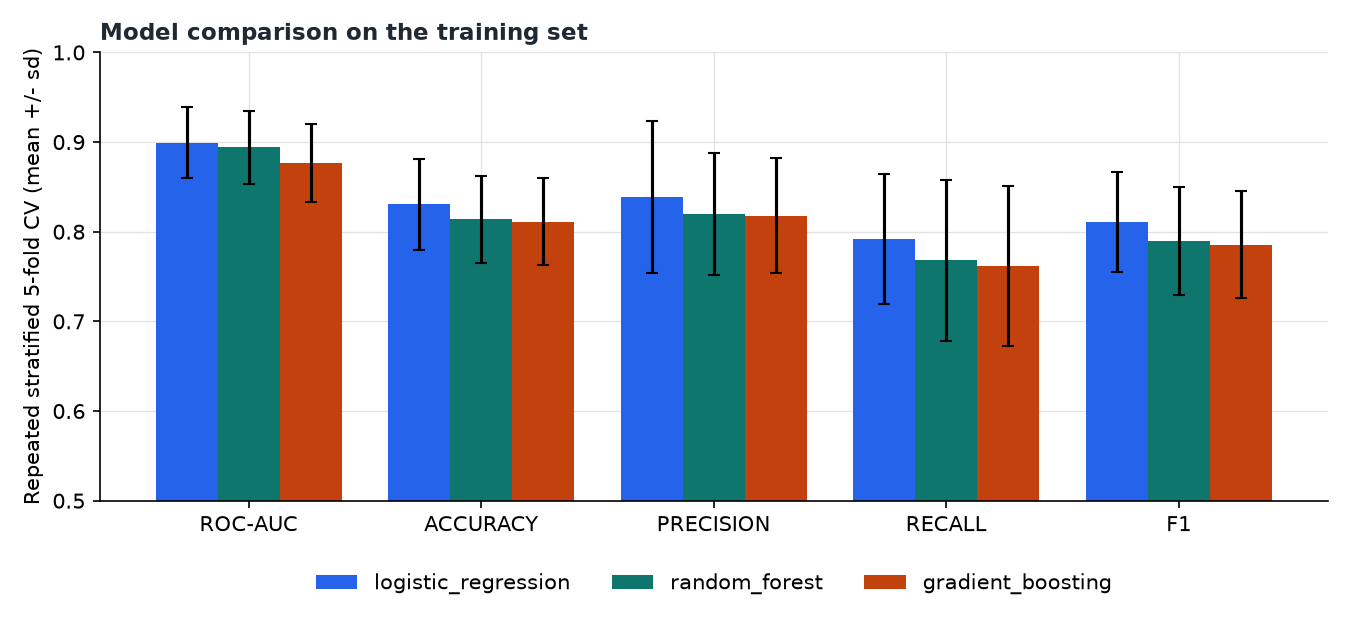

In [5]:
display(Image(filename=str(config.FIGURES_DIR / "model_comparison.png"), width=820))

## 3. Hyper-parameter search (all candidates)

In [6]:
cands = runs[runs["tags.stage"] == "candidate"]
top = cands.sort_values("metrics.cv_roc_auc_mean", ascending=False)
pcols = [c for c in cands.columns if c.startswith("params.")]
top[["tags.model_family", "metrics.cv_roc_auc_mean", "metrics.cv_roc_auc_std"] + pcols].head(12).round(4)

,tags.model_family,metrics.cv_roc_auc_mean,metrics.cv_roc_auc_std,params.best_C,params.decision_threshold,params.test_rows,params.best_l1_ratio,params.best_fe_enabled,params.data_sha256,params.best_class_weight,...,params.max_features,params.best_max_features,params.fixed_n_estimators,params.fixed_n_jobs,params.best_min_samples_leaf,params.class_weight,params.l1_ratio,params.C,params.fixed_max_iter,params.fixed_solver
71,logistic_regression,0.8994,0.0392,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,balanced,0.0,0.1,NaN,NaN
77,logistic_regression,0.8994,0.0396,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,None,0.0,0.1,NaN,NaN
65,logistic_regression,0.8975,0.0416,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,None,0.0,0.3,NaN,NaN
63,logistic_regression,0.8973,0.0418,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,None,0.5,0.3,NaN,NaN
59,logistic_regression,0.8972,0.0415,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,balanced,0.0,0.3,NaN,NaN
72,logistic_regression,0.8970,0.0414,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,balanced,0.0,0.1,NaN,NaN
58,logistic_regression,0.8970,0.0404,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,balanced,0.5,0.3,NaN,NaN
78,logistic_regression,0.8969,0.0421,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,None,0.0,0.1,NaN,NaN
57,logistic_regression,0.8968,0.0417,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,balanced,0.5,0.3,NaN,NaN
64,logistic_regression,0.8965,0.0407,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,None,0.5,0.3,NaN,NaN


## 4. Ablation: do the engineered clinical features help?
`features__enabled` is a grid parameter, so every model family was evaluated with and without them.

In [7]:
import ast
rows = []
for fam in cfg["models"]:
    r = pd.read_csv(config.REPORTS_DIR / "evaluation" / fam / "cv_results.csv")
    r["engineered"] = r["params"].map(lambda s: ast.literal_eval(s)["features__enabled"])
    best = r.groupby("engineered")["mean_test_roc_auc"].max()
    rows.append({"model": fam, "best CV AUC without": best[False], "best CV AUC with": best[True],
                 "delta": best[True] - best[False]})
pd.DataFrame(rows).round(4)

,model,best CV AUC without,best CV AUC with,delta
0,logistic_regression,0.8994,0.8970,-0.0024
1,random_forest,0.8940,0.8913,-0.0027
2,gradient_boosting,0.8761,0.8767,0.0007


**Result:** the engineered features change CV ROC-AUC by less than 0.005 in every family - well inside one CV standard deviation (~0.04). The linear model already combines `age` and `thalach`, so the ratio adds little. The grid therefore kept the simpler feature set for the champion; the transformer stays in the pipeline (disabled) so the ablation is reproducible.

## 5. Champion, operating threshold and hold-out evaluation

In [8]:
card = json.loads(config.MODEL_CARD_PATH.read_text())
print("Champion:", card["model_type"], "|", card["selection_reason"])
print("Hyper-parameters:", card["hyperparameters"])
print("Threshold:", card["decision_threshold"], "-", card["threshold_policy"])
pd.DataFrame({"threshold 0.50": card["test_metrics_threshold_0_5"],
              f"threshold {card['decision_threshold']}": card["test_metrics_tuned_threshold"],
              "external (Hungarian)": card["external_validation_hungarian"]}).round(3)

Champion: logistic_regression | highest CV roc_auc
Hyper-parameters: {'clf__C': 0.1, 'clf__class_weight': 'balanced', 'clf__l1_ratio': 0.0, 'features__enabled': False}
Threshold: 0.31 - max F2 on out-of-fold train predictions, precision >= 0.6


,threshold 0.50,threshold 0.31,external (Hungarian)
accuracy,0.885,0.820,0.833
precision,0.839,0.718,0.752
recall,0.929,1.000,0.802
specificity,0.848,0.667,0.850
f1,0.881,0.836,0.776
f2,0.909,0.927,0.791
roc_auc,0.961,0.961,0.894
pr_auc,0.949,0.949,0.857
brier,0.091,0.091,0.133
tp,26.000,28.000,85.000


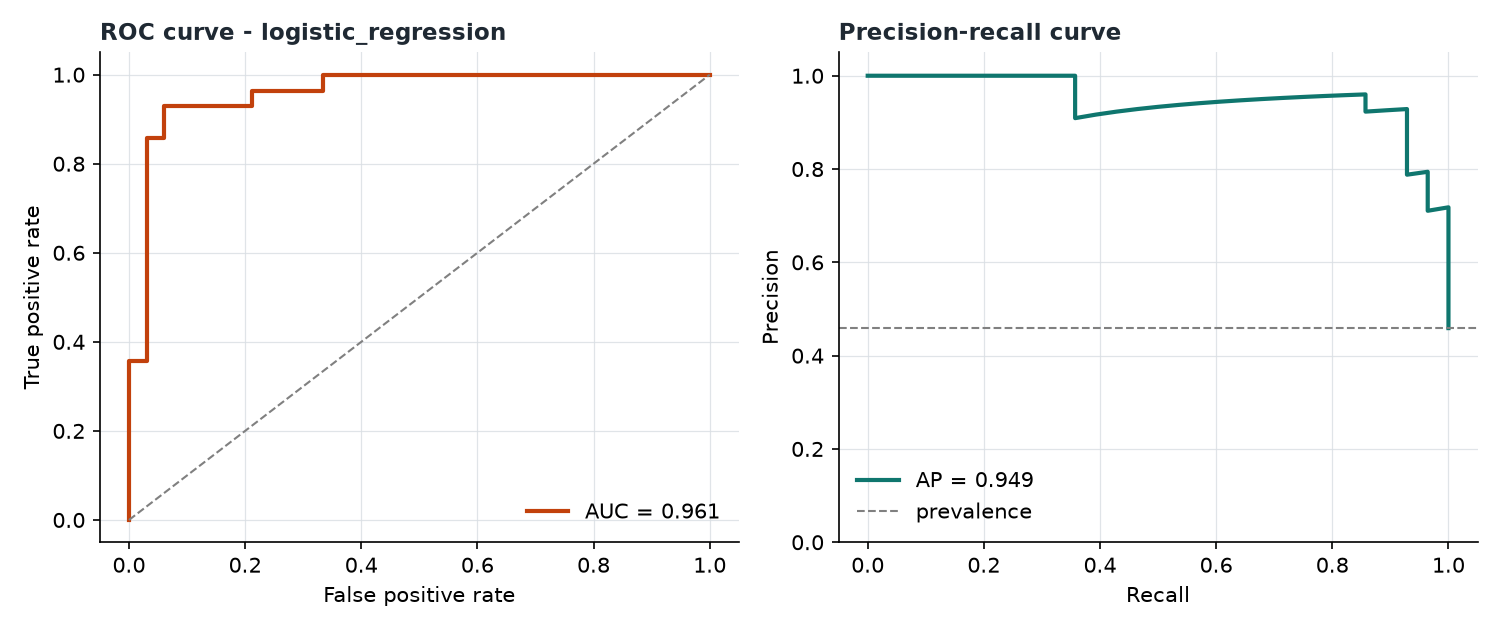

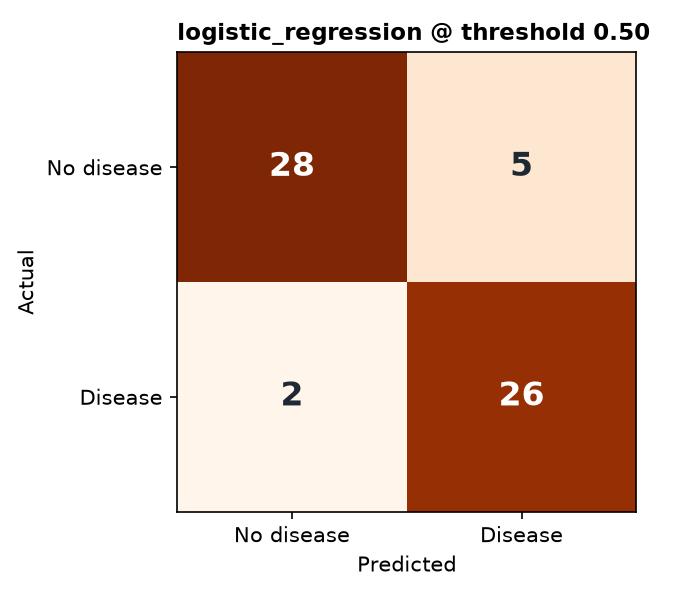

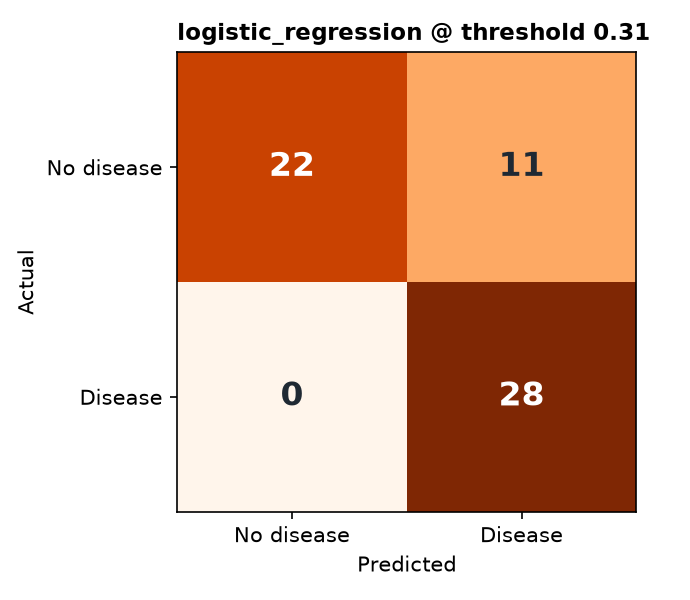

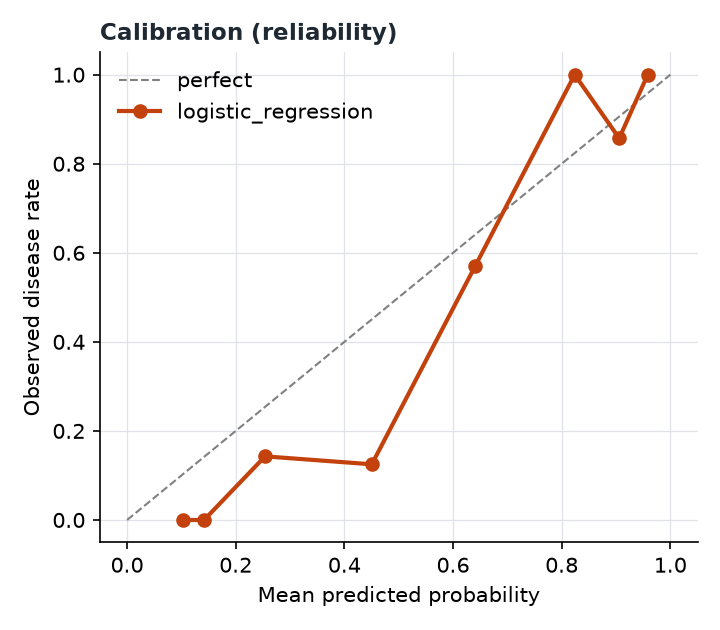

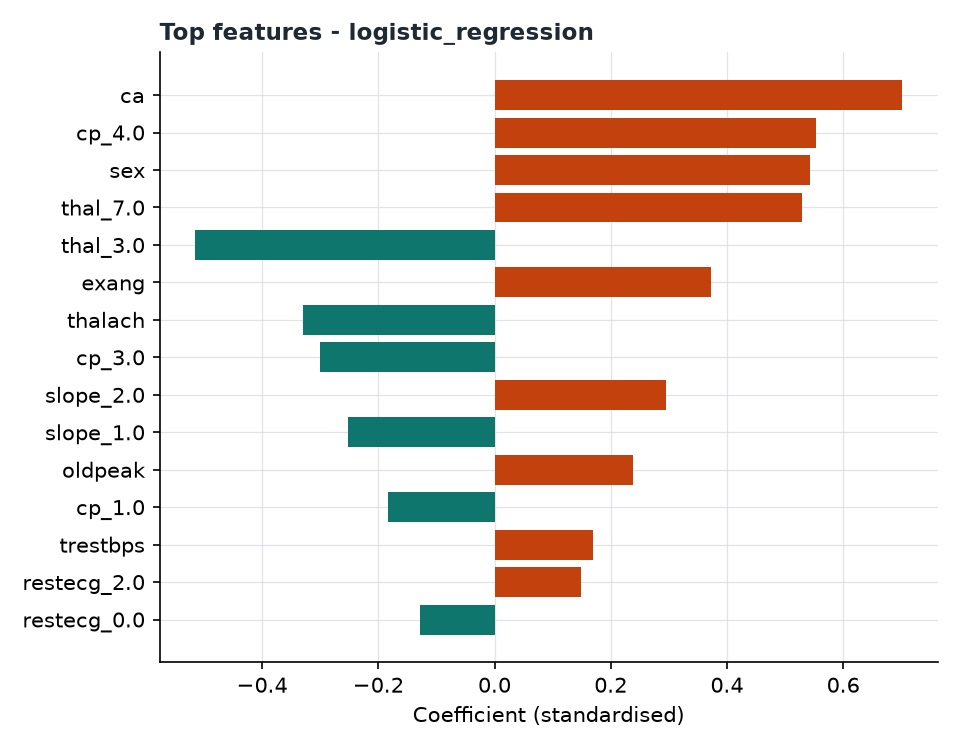

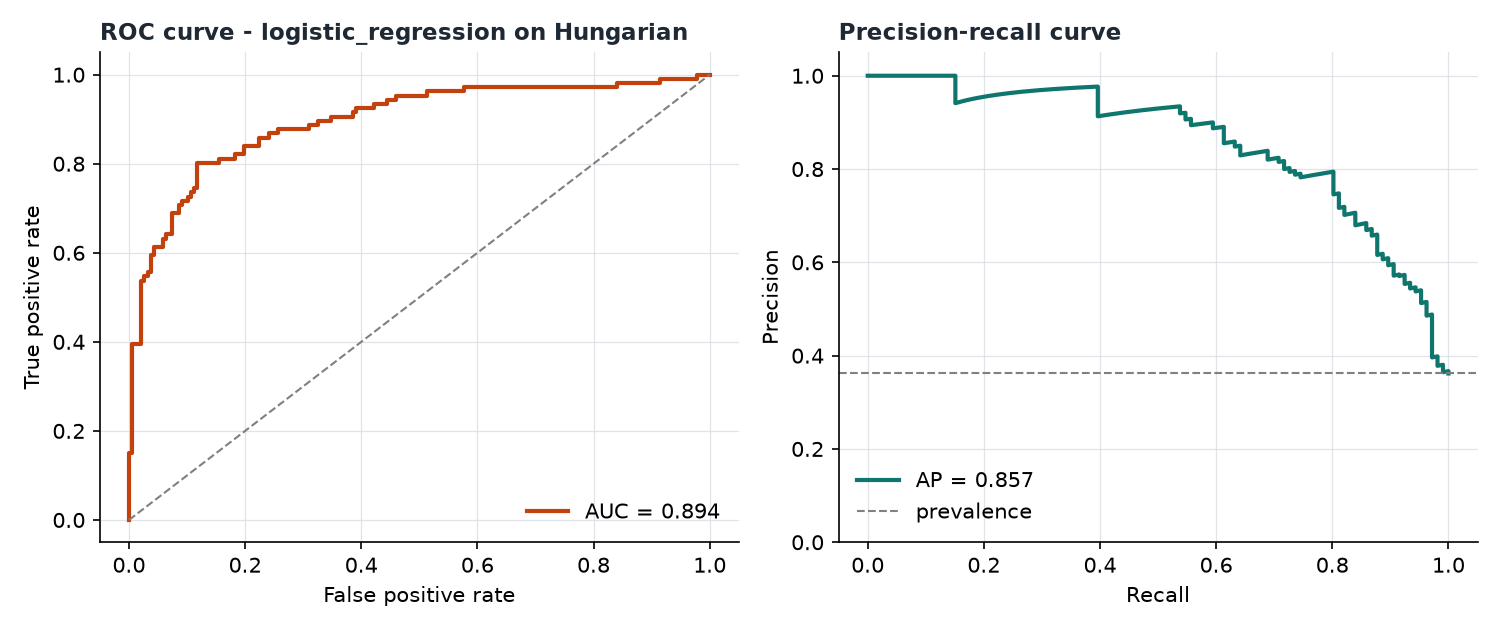

In [9]:
for f in ["champion_roc_pr.png", "champion_confusion_default.png", "champion_confusion_tuned.png",
          "champion_calibration.png", "champion_feature_importance.png", "external_hungarian_roc_pr.png"]:
    display(Image(filename=str(config.FIGURES_DIR / f), width=640))

## 6. Reading the results critically
* **Hold-out (61 patients) is optimistic**: test ROC-AUC 0.96 vs 0.90 in repeated CV. With n = 61, one patient moves accuracy by 1.6 points; the CV estimate is the number to quote.
* **Threshold 0.31 trades 6 extra false alarms for 2 fewer missed cases** on the hold-out - the intended screening behaviour, chosen on out-of-fold training predictions, never on the test set.
* **External site**: ROC-AUC holds at ~0.89 on Hungarian patients despite `ca`/`thal` being almost entirely imputed, but recall falls - a re-calibration would be needed before using it at another hospital.
* **Registry**: the champion is registered as `heart-disease-classifier` with alias `champion`.

In [10]:
client = mlflow.MlflowClient()
mv = client.get_model_version_by_alias(config.REGISTERED_MODEL_NAME, "champion")
print(mv.name, "version", mv.version, "|", mv.description)

heart-disease-classifier version 1 | logistic_regression | test ROC-AUC 0.961 | threshold 0.31
